In [363]:
pip install numpy matplotlib scikit-learn pandas xgboost tensorflow keras seaborn scikeras

Note: you may need to restart the kernel to use updated packages.


### Importation des librairies

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import SVC
from xgboost import XGBClassifier
import warnings
warnings.simplefilter('ignore')

from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical
from keras.metrics import AUC
from sklearn.metrics import confusion_matrix


### Importation du jeu de données

Nous importons le jeu de données généré par le script créer_dataset : 72 features (+ itemid, dataset, et hasbird) sur 15 690 audios

In [ ]:
features_birds = pd.read_csv("features_oiseaux.csv")

print(features_birds.head())

   itemid dataset  hasbird   ae_mean    ae_std    ae_min    ae_max  rms_mean  \
0   64486      ff        0  0.321359  0.145708  0.050087  0.710800  0.111805   
1    2525      ff        0  0.138455  0.118639  0.027378  0.695111  0.055308   
2   44981      ff        0  0.111837  0.024839  0.070895  0.250569  0.033378   
3  101323      ff        0  0.372752  0.088272  0.210752  0.732493  0.116766   
4  165746      ff        0  0.002218  0.000566  0.001247  0.005916  0.000603   

    rms_std   rms_min  ...  mfcc11_min  mfcc11_max  mfcc12_mean  mfcc12_std  \
0  0.046613  0.020638  ...  -47.773598   13.676870    -1.258360    8.832997   
1  0.046761  0.009306  ...  -20.808870   14.128860     4.286780    4.940105   
2  0.004733  0.026048  ...  -23.683109    4.280350     3.719182    4.841701   
3  0.018330  0.083100  ...  -14.136223   17.492676     4.860087    4.869281   
4  0.000071  0.000435  ...  -21.500742    9.829727     1.839618    5.445219   

   mfcc12_min  mfcc12_max  mfcc13_mean  mfcc

In [366]:
features_birds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15690 entries, 0 to 15689
Data columns (total 75 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   itemid          15690 non-null  object 
 1   dataset         15690 non-null  object 
 2   hasbird         15690 non-null  int64  
 3   ae_mean         15690 non-null  float64
 4   ae_std          15690 non-null  float64
 5   ae_min          15690 non-null  float64
 6   ae_max          15690 non-null  float64
 7   rms_mean        15690 non-null  float64
 8   rms_std         15690 non-null  float64
 9   rms_min         15690 non-null  float64
 10  rms_max         15690 non-null  float64
 11  zcr_mean        15690 non-null  float64
 12  zcr_std         15690 non-null  float64
 13  zcr_min         15690 non-null  float64
 14  zcr_max         15690 non-null  float64
 15  centroid_mean   15690 non-null  float64
 16  centroid_std    15690 non-null  float64
 17  centroid_min    15690 non-null 

Notre jeu de données a été correctement importé (toutes les features sont correctement typées en float64)

In [367]:
libelle = ["Pas d'oiseau", "Oiseau"]
features_birds['hasbird'].value_counts(normalize=True, sort=False)

hasbird
0    0.491396
1    0.508604
Name: proportion, dtype: float64

Nous sommes dans un cadre bien équilibré.

In [368]:
str = features_birds.select_dtypes(exclude='number').columns
num = features_birds.select_dtypes(include='number').columns.drop('hasbird')

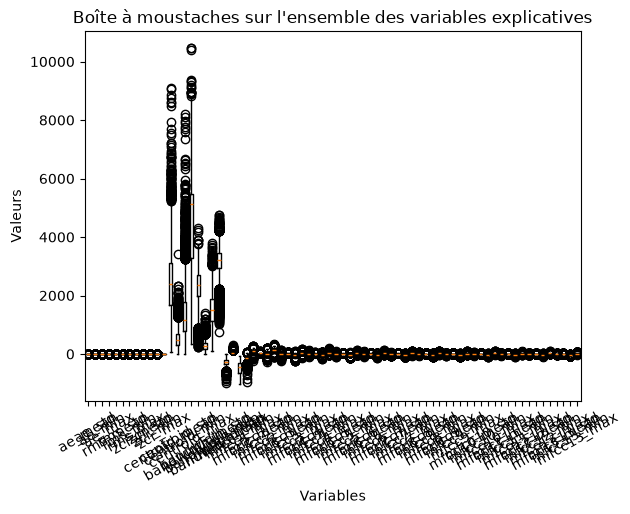

In [369]:
# Boîtes à moustaches sur l'ensemble des variables explicatives
plt.boxplot(features_birds[num])
plt.xticks(np.arange(1,len(features_birds[num].columns)+1), features_birds[num].columns,rotation=30)   
plt.xlabel('Variables')
plt.ylabel('Valeurs')
plt.title("Boîte à moustaches sur l'ensemble des variables explicatives")
plt.show()

In [370]:
features_birds[num].describe()

,ae_mean,ae_std,ae_min,ae_max,rms_mean,rms_std,rms_min,rms_max,zcr_mean,zcr_std,...,mfcc11_min,mfcc11_max,mfcc12_mean,mfcc12_std,mfcc12_min,mfcc12_max,mfcc13_mean,mfcc13_std,mfcc13_min,mfcc13_max
count,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,...,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000,15690.000000
mean,0.181778,0.095096,0.047460,0.650292,0.065273,0.031562,0.020175,0.217644,0.146921,0.058258,...,-29.905548,15.051488,-1.722943,6.861399,-22.906540,19.990819,-6.270030,6.653465,-26.900092,14.444759
std,0.118776,0.042234,0.072583,0.143393,0.047013,0.021179,0.028297,0.099294,0.095895,0.039243,...,13.352265,10.917919,7.585268,2.337211,11.683277,10.271208,7.179339,2.161716,10.703593,9.790583
min,-0.496296,0.000566,-0.531079,-0.310907,0.000128,0.000071,0.000007,0.000976,0.000000,0.000000,...,-89.486328,-20.196011,-43.672203,0.927370,-89.938255,-17.450155,-37.815571,0.588323,-85.219284,-18.810318
25%,0.090306,0.065102,0.000034,0.559923,0.029450,0.016900,0.000008,0.149648,0.074307,0.024514,...,-38.265202,7.017802,-6.867912,5.239474,-29.578643,12.891125,-11.416337,5.174524,-33.298250,7.415254
50%,0.158667,0.088150,0.014019,0.688784,0.055108,0.027966,0.006664,0.215210,0.129689,0.054351,...,-28.763777,13.512672,-2.649961,6.205214,-21.926048,18.792148,-7.307183,6.040818,-26.198120,13.033058
75%,0.257630,0.117070,0.072990,0.773075,0.092996,0.040920,0.031471,0.272377,0.200705,0.081110,...,-20.133100,20.830323,3.763408,7.758450,-14.678240,25.366565,-1.078004,7.468266,-19.272085,19.334836
max,0.802685,0.354013,0.669857,1.046824,0.554387,0.226470,0.395368,0.794169,0.914921,0.367832,...,22.493187,87.153107,46.819317,42.381668,37.471489,102.365997,32.856518,42.500942,8.261097,78.152847


Nous constatons des problèmes d'échelles entre les features issues des coefficients MFCC et les autres features. Nous corrigerons ce problème d'échelle de grandeur après l'extraction des ensembles d'apprentissage et de test.

### Séparation des données en ensembles d'apprentissage/test

In [371]:
## Séparation des variables explicatives et de la variable cible
X = features_birds.drop(["hasbird", "itemid", "dataset"], axis=1)
y = features_birds.hasbird

## Séparation des données en ensembles d'entraînement et de test
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Mise à l'échelle des données
scale = StandardScaler()
Xtrain = scale.fit_transform(Xtrain)
Xtest = scale.transform(Xtest)

### Construction des modèles prédictifs

Pour la suite, nous construirons des modèles prédictifs selon une procédure commune avec comme metric l'accuracy (puisque notre cadre est bien équilibré) :
- Validation croisée stratifiée (avec 5 plis) du modèle avec les hyperparamètres par défaut
- Optimisation des hyperparamètres par recherche aléatoire en validation croisée stratifiée
- Prédiction sur l'échantillon de tests et calcul de l'accuracy pour nos deux modèles
- Production de la matrice de confusion et du rapport de classification pour le modèle dont les hyperparamètres ont été optimisés

In [372]:
### Validation croisée stratifiée à 5 folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#### Régression Logistique

Ce modèle servira de point de repère à dépasser pour les autres modèles prédictifs.

In [373]:
regLog = LogisticRegression(random_state = 42)
cross_regLog = cross_validate(regLog, Xtrain, ytrain, cv = skf, return_train_score=True, scoring='accuracy', n_jobs=-1)

In [374]:
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {cross_regLog['train_score'].mean()*100:.2f}%, pour un écart-type de {cross_regLog['train_score'].std():.4f}")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {cross_regLog['test_score'].mean()*100:.2f}%, pour un écart-type de {cross_regLog['test_score'].std():.4f}")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 82.54%, pour un écart-type de 0.0013
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 82.15%, pour un écart-type de 0.0032


In [375]:
regLog_default = regLog.fit(Xtrain, ytrain)
yPred_regLog = regLog_default.predict(Xtest)

print(f"Sur les données de test, nous obtenons une accuracy de {regLog_default.score(Xtest, ytest)*100:.2f}%")

Sur les données de test, nous obtenons une accuracy de 81.64%


Text(0.5, 427.9555555555555, 'Affectations')

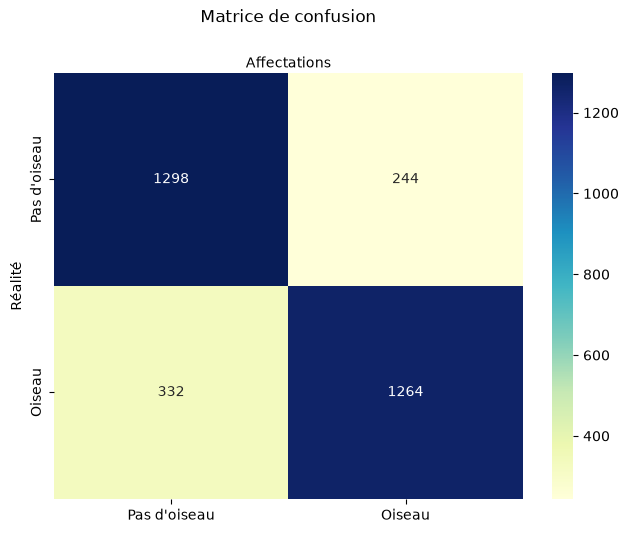

In [376]:
## Matrice de confusion
confusion_regLog = pd.DataFrame(confusion_matrix(ytest, yPred_regLog), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_regLog), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [377]:
## Rapport de classification
print(classification_report(ytest, yPred_regLog, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.80      0.84      0.82      1542
      Oiseau       0.84      0.79      0.81      1596

    accuracy                           0.82      3138
   macro avg       0.82      0.82      0.82      3138
weighted avg       0.82      0.82      0.82      3138



Avec une simple Régression Logistique sur l'ensemble des features, nous obtenons un modèle avec un taux de bien classés moyen plutôt élevé - à la fois sur l'ensemble d'apprentissage et l'ensemble de validation - de près de 82%. Qui plus est, au vu des écarts-types plutôt faibles (respectivement 0.0013 et 0.0032), les prédictions sont plut^t stable. Sur les données de tests, nous obtenons un taux de bien classés proche. En regardant dans le détail les prédictions nous constatons que ce modèle prédit aussi bien la présence d'oiseaux dans les audios que leur absence (1264 et 1298). Nous remarquons tout de même que le modèle a légèrement tendance à prédire l'absence d'oiseaux.
Aussi, au vu du faible écart dans les taux de bien classés, nous ne présageons pas de surapprentissage dans les données. Mais par curiosité, nous décidons de tester les méthodes de régularisation.

#### Régression Logistique régularisée

In [378]:
grille = {
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'C': [0.01, 0.1, 1, 10, 100]
}
regLogRegul = LogisticRegression(random_state = 42, solver='saga')
best_regLogRegul = RandomizedSearchCV(estimator = regLogRegul, param_distributions = grille, cv = skf, n_jobs=-1, scoring='accuracy')
best_regLogRegul.fit(Xtrain, ytrain)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=LogisticRegression(random_state=42, solver='saga'),
                   n_jobs=-1,
                   param_distributions={'C': [0.01, 0.1, 1, 10, 100],
                                        'penalty': ['l1', 'l2', 'elasticnet',
                                                    'none']},
                   scoring='accuracy')

In [379]:
print("Meilleurs paramètres :", best_regLogRegul.best_params_)
print(f"Meilleure accuracy de validation : {best_regLogRegul.best_score_*100:.2f}%")

Meilleurs paramètres : {'penalty': 'l2', 'C': 10}
Meilleure accuracy de validation : 82.23%


In [380]:
best_regLogRegul_eval=best_regLogRegul.best_estimator_
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {best_regLogRegul_eval.score(Xtrain, ytrain)*100:.2f}%")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {best_regLogRegul_eval.score(Xtest, ytest)*100:.2f}%")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 82.57%
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 81.55%


Text(0.5, 427.9555555555555, 'Affectations')

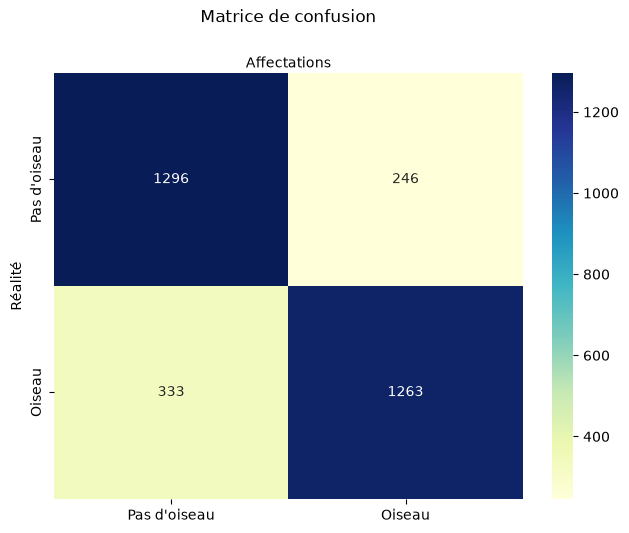

In [381]:
yPred_regLogRegul = best_regLogRegul.predict(Xtest)
## Matrice de confusion
confusion_regLogRegul = pd.DataFrame(confusion_matrix(ytest, yPred_regLogRegul), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_regLogRegul), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [382]:
## Rapport de classification
print(classification_report(ytest, yPred_regLogRegul, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.80      0.84      0.82      1542
      Oiseau       0.84      0.79      0.81      1596

    accuracy                           0.82      3138
   macro avg       0.82      0.82      0.82      3138
weighted avg       0.82      0.82      0.82      3138



Etant donné que nous ne sommes pas dans un problème de Haute-Dimension et que la Régression Logistique "classique" ne présentait pas de suraprentissage, la similitude des résultats est logique.

#### Arbre de décision

In [383]:
## Arbre de décision complet
decTree = DecisionTreeClassifier(random_state = 42)
cross_decTree = cross_validate(decTree, Xtrain, ytrain, cv = skf, return_train_score=True, n_jobs=-1, scoring='accuracy')

In [384]:
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {cross_decTree['train_score'].mean()*100:.2f}%, pour un écart-type de {cross_decTree['train_score'].std():.4f}")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {cross_decTree['test_score'].mean()*100:.2f}%, pour un écart-type de {cross_decTree['test_score'].std():.4f}")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 100.00%, pour un écart-type de 0.0000
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 73.88%, pour un écart-type de 0.0062


In [385]:
decTree_default = decTree.fit(Xtrain, ytrain)
yPred_decTree = decTree_default.predict(Xtest)

print(f"Sur les données de test, nous obtenons une accuracy de {decTree_default.score(Xtest, ytest)*100:.2f}%")

Sur les données de test, nous obtenons une accuracy de 74.35%


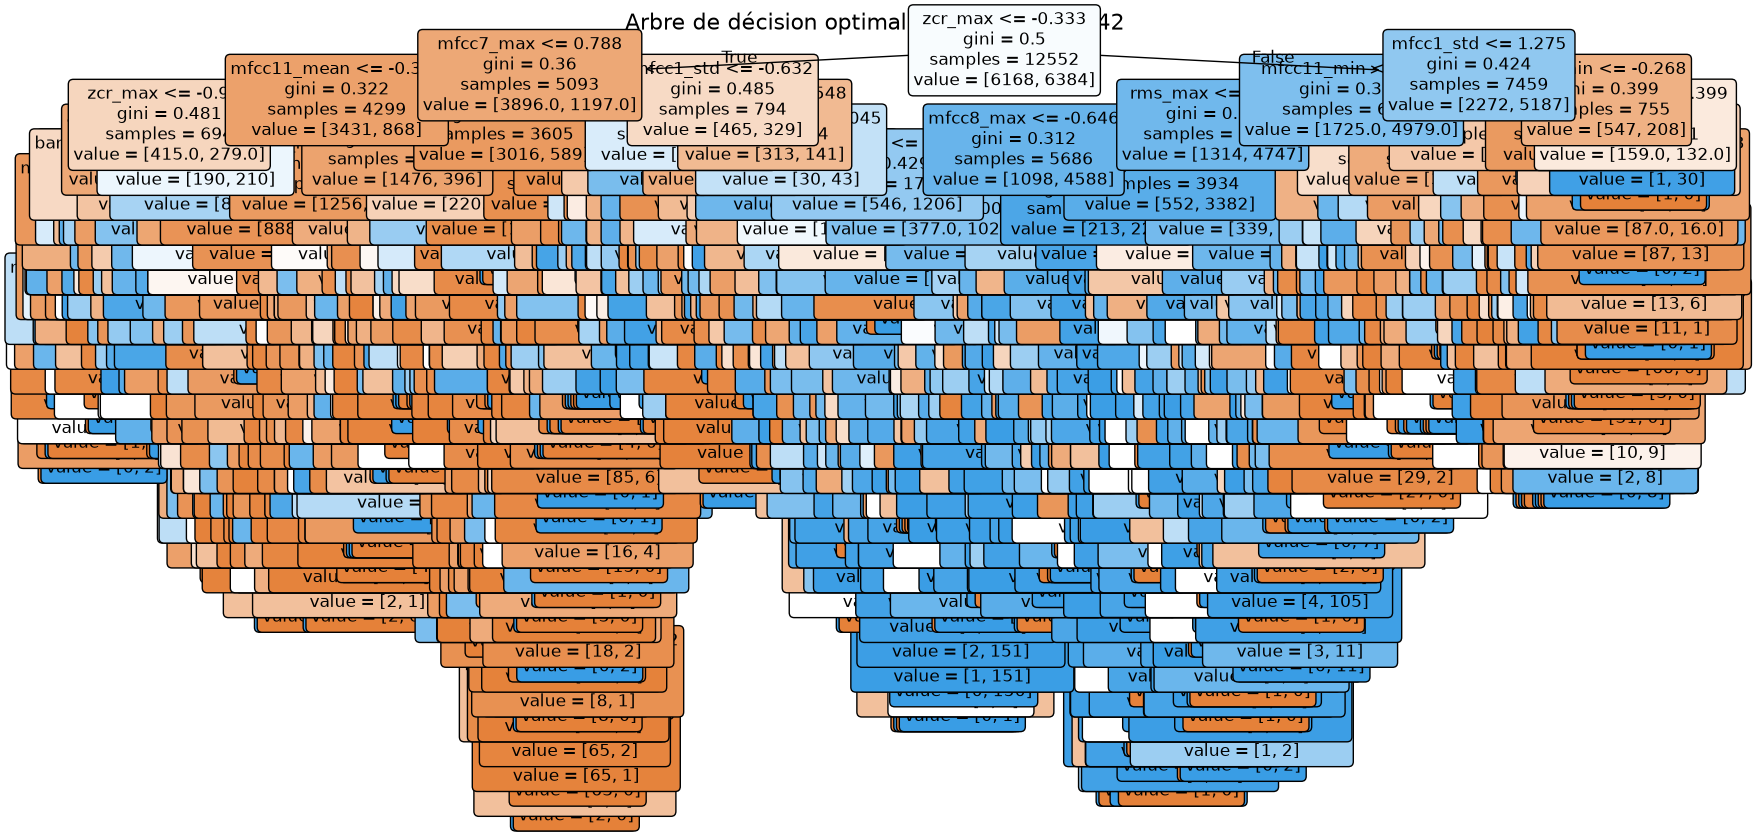

In [386]:
# Visualisation de l'arbre optimal
plt.figure(figsize=(20, 10))
ax = plt.gca()  # Récupérer l'axe du graphique

# Tracer l'arbre
plot_tree(
    decTree_default, 
    feature_names=X.columns,
    filled=True, 
    rounded=True, 
    fontsize=12
)

# Changer la couleur de la police des nœuds
for label in ax.texts:
    label.set_color('black')  # Changer la couleur des étiquettes en bleu

# Changer la couleur du titre
plt.title("Arbre de décision optimal random_state = 42", fontsize=16)

plt.show()

Avec un arbre de décision complet, les performances se sont nettement dégradés. En effet, le taux de bien classés moyen des ensembles de validation est de 73.88% (écart-type moyen de 0.0062), soit près de 9 points de % en deçà des performances de la Régression Logistique. Qui plus est, nous constatons un fort surapprentissage avec un taux de bien classés moyen des ensembles d'apprentissages de 100%. Ce surapprentissage est causé par la complexité de l'arbre, puisqu'aucun élagage n'est réalisé. Réalisons donc une recherche aléatoire sur les hyperparamètres.

In [387]:
# Définir la grille de recherche des hyperparamètres
grille_decTree = {
    'max_depth': [1, 2, 3, 4, 5, 10, 15, None],
    'min_samples_split': [2, 3, 4, 5],
    'min_samples_leaf': [1, 2, 3, 4, 5],
    'criterion': ['log_loss', 'gini', 'entropy'],
    'max_leaf_nodes': [None, 5, 10, 15, 20],
}
decTree = DecisionTreeClassifier(random_state = 42)
best_decTree = RandomizedSearchCV(estimator = decTree, param_distributions = grille_decTree, cv = skf, scoring='accuracy', n_jobs=-1, random_state=42)
best_decTree.fit(Xtrain, ytrain)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
                   param_distributions={'criterion': ['log_loss', 'gini',
                                                      'entropy'],
                                        'max_depth': [1, 2, 3, 4, 5, 10, 15,
                                                      None],
                                        'max_leaf_nodes': [None, 5, 10, 15, 20],
                                        'min_samples_leaf': [1, 2, 3, 4, 5],
                                        'min_samples_split': [2, 3, 4, 5]},
                   random_state=42, scoring='accuracy')

In [388]:
best_decTree_eval=best_decTree.best_estimator_
print("Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour cet arbre de décision :\n {}; \n nous obtenons une accuracy de {:.2f}% sur les données d'apprentissage et de {:.2f}% sur les données de test.".format(best_decTree.best_params_, best_decTree_eval.score(Xtrain, ytrain)*100, best_decTree_eval.score(Xtest, ytest)*100))
yPred_decTree = best_decTree_eval.predict(Xtest)

Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour cet arbre de décision :
 {'min_samples_split': 4, 'min_samples_leaf': 4, 'max_leaf_nodes': 20, 'max_depth': 5, 'criterion': 'gini'}; 
 nous obtenons une accuracy de 79.45% sur les données d'apprentissage et de 78.27% sur les données de test.


Text(0.5, 427.9555555555555, 'Affectations')

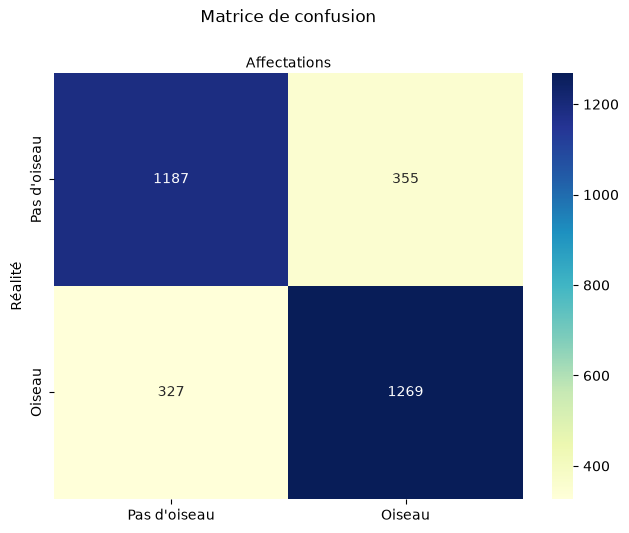

In [389]:
# Matrice de confusion
confusion_decTree = pd.DataFrame(confusion_matrix(ytest, yPred_decTree), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_decTree), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [390]:
## Rapport de classification
print(classification_report(ytest, yPred_decTree, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.78      0.77      0.78      1542
      Oiseau       0.78      0.80      0.79      1596

    accuracy                           0.78      3138
   macro avg       0.78      0.78      0.78      3138
weighted avg       0.78      0.78      0.78      3138



Avec cet arbre de décision dont nous avons cherché la meilleure configuration d'hyperparamètres par RandomizedSearchCV, nous obtenons de meilleures performances que l'arbre de décision initiale. En effet, nous obtenons une accuracy de 79.45% sur les données d'apprentissage. La capacité de généralisation de ce modèle est très bon, puisque l'accuracy sur les données de test est de 78.27%, soit un écart de près de 1 point de pourcentage. En regardant dans le détail les prédictions, nous constatons une plus grand difficulté à classer correctement les audios pour lesquels les chants d'oiseaux sont absents (1187 audios sans chants bien affectés contre 1269 audios avec chants).
Malgré tout, le niveau de performances est plus faible qu'avec une Régression Logistique. Nous décidons donc de construire une forêt aléatoire.

#### Random Forest

In [391]:
rf = RandomForestClassifier(random_state = 42)
cross_rf = cross_validate(rf, Xtrain, ytrain, cv = skf, return_train_score=True, scoring='accuracy', n_jobs=-1)

In [392]:
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {cross_rf['train_score'].mean()*100:.2f}%, pour un écart-type de {cross_rf['train_score'].std():.4f}")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {cross_rf['test_score'].mean()*100:.2f}%, pour un écart-type de {cross_rf['test_score'].std():.4f}")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 100.00%, pour un écart-type de 0.0000
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 83.73%, pour un écart-type de 0.0028


In [393]:
rf_default = rf.fit(Xtrain, ytrain)
yPred_rf = rf_default.predict(Xtest)

print(f"Sur les données de test, nous obtenons une accuracy de {rf_default.score(Xtest, ytest)*100:.2f}%")

Sur les données de test, nous obtenons une accuracy de 83.56%


Le Random Forest avec les hyperparamètres de bases présentent un meilleur taux de bien classés moyen sur les ensembles de validation qu'avec la Régression Logistique (83.73% contre 82.15%). Mais le taux de bien classés moyen de 100% sur les ensembles d'apprentissage indique un surapprentissage. Réalisons un RandomizedSearchCV pour réduire la complexité.

In [394]:
grille_rf = {
    'n_estimators':[10, 50, 100, 150, 200, 500],
    'max_features':['log2', 'sqrt'],
    'max_depth':[4, 8, 10, 15, None],
    'criterion':['gini', 'entropy'],
    'class_weight':['balanced', None]
}
rf = RandomForestClassifier(random_state = 42)
best_rf = RandomizedSearchCV(estimator = rf, param_distributions = grille_rf, cv = skf, scoring='accuracy', n_jobs=-1, random_state=42)
best_rf.fit(Xtrain, ytrain)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
                   param_distributions={'class_weight': ['balanced', None],
                                        'criterion': ['gini', 'entropy'],
                                        'max_depth': [4, 8, 10, 15, None],
                                        'max_features': ['log2', 'sqrt'],
                                        'n_estimators': [10, 50, 100, 150, 200,
                                                         500]},
                   random_state=42, scoring='accuracy')

In [395]:
best_rf_eval=best_rf.best_estimator_
print("Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le random forest :\n {}; \n nous obtenons une accuracy de {:.2f}% sur les données d'apprentissage et de {:.2f}% sur les données de test.".format(best_rf.best_params_, best_rf_eval.score(Xtrain, ytrain)*100, best_rf_eval.score(Xtest, ytest)*100))
yPred_rf = best_rf_eval.predict(Xtest)

Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le random forest :
 {'n_estimators': 500, 'max_features': 'log2', 'max_depth': None, 'criterion': 'entropy', 'class_weight': None}; 
 nous obtenons une accuracy de 100.00% sur les données d'apprentissage et de 83.30% sur les données de test.


Text(0.5, 427.9555555555555, 'Affectations')

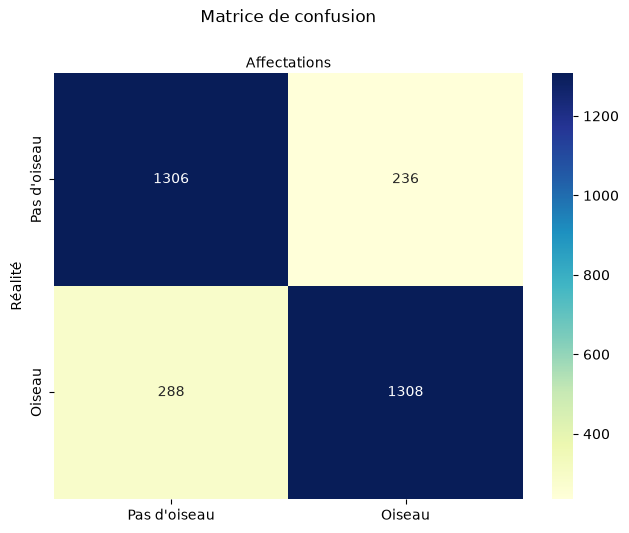

In [396]:
# Matrice de confusion
confusion_rf = pd.DataFrame(confusion_matrix(ytest, yPred_rf), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_rf), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [397]:
## Rapport de classification
print(classification_report(ytest, yPred_rf, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.82      0.85      0.83      1542
      Oiseau       0.85      0.82      0.83      1596

    accuracy                           0.83      3138
   macro avg       0.83      0.83      0.83      3138
weighted avg       0.83      0.83      0.83      3138



Le Random Forest avec la meilleure configuration d'hyperparamètres trouvée par RandomizedSearchCV ne présente pas des performances différentes du Random Forest avec les hyperparamètres par défaut. Si nous regardons plus dans le détail les prédictions, nous pouvons constater que le Random Forest prédit relativement équitablement les audios avec chants d'oiseaux et les audios sans chants d'oiseaux. Nous remarquons tout de même qu'il a un peu plus tendance à affecter en 'Pas d'oiseaux'.

#### SVM Linéaire

In [398]:
svmLin = SVC(kernel = 'linear', random_state=42)
cross_svmLin = cross_validate(svmLin, Xtrain, ytrain, cv = skf, return_train_score=True, scoring='accuracy', n_jobs=-1)

In [399]:
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {cross_svmLin['train_score'].mean()*100:.2f}%, pour un écart-type de {cross_svmLin['train_score'].std():.4f}")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {cross_svmLin['test_score'].mean()*100:.2f}%, pour un écart-type de {cross_svmLin['test_score'].std():.4f}")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 82.47%, pour un écart-type de 0.0018
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 82.03%, pour un écart-type de 0.0029


In [400]:
svmLin_default = svmLin.fit(Xtrain, ytrain)
yPred_svmLin = svmLin_default.predict(Xtest)

print(f"Sur les données de test, nous obtenons une accuracy de {svmLin_default.score(Xtest, ytest)*100:.2f}%")

Sur les données de test, nous obtenons une accuracy de 81.64%


In [401]:
grille_svmLin = {
    'C': np.linspace(0,20,100),
    'class_weight': ['balanced', None]
}
svmLin = SVC(kernel='linear', random_state=42)
best_svmLin = RandomizedSearchCV(estimator = svmLin, param_distributions = grille_svmLin, cv = skf, scoring='accuracy', n_jobs=-1, random_state=42)
best_svmLin.fit(Xtrain, ytrain)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=SVC(kernel='linear', random_state=42), n_jobs=-1,
                   param_distributions={'C': array([ 0.        ,  0.2020202 ,  0.4040404 ,  0.60606061,  0.80808081,
        1.01010101,  1.21212121,  1.41414141,  1.61616162,  1.81818182,
        2.02020202,  2.22222222,  2.42424242,  2.62626263,  2.82828283,
        3.03030303,  3.23232323,  3.434...
       15.15151515, 15.35353535, 15.55555556, 15.75757576, 15.95959596,
       16.16161616, 16.36363636, 16.56565657, 16.76767677, 16.96969697,
       17.17171717, 17.37373737, 17.57575758, 17.77777778, 17.97979798,
       18.18181818, 18.38383838, 18.58585859, 18.78787879, 18.98989899,
       19.19191919, 19.39393939, 19.5959596 , 19.7979798 , 20.        ]),
                                        'class_weight': ['balanced', None]},
                   random_state=42, scoring='accuracy')

In [402]:
best_svmLin_eval=best_svmLin.best_estimator_
print("Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le SVM linéaire : \n {}; \n nous obtenons une accuracy de {:.2f}% sur les données d'apprentissage et de {:.2f}% sur les données de test.".format(best_svmLin.best_params_, best_svmLin_eval.score(Xtrain, ytrain)*100, best_svmLin_eval.score(Xtest, ytest)*100))
yPred_svmLin = best_svmLin_eval.predict(Xtest)

Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le SVM linéaire : 
 {'class_weight': None, 'C': 1.4141414141414141}; 
 nous obtenons une accuracy de 82.43% sur les données d'apprentissage et de 81.61% sur les données de test.


Text(0.5, 427.9555555555555, 'Affectations')

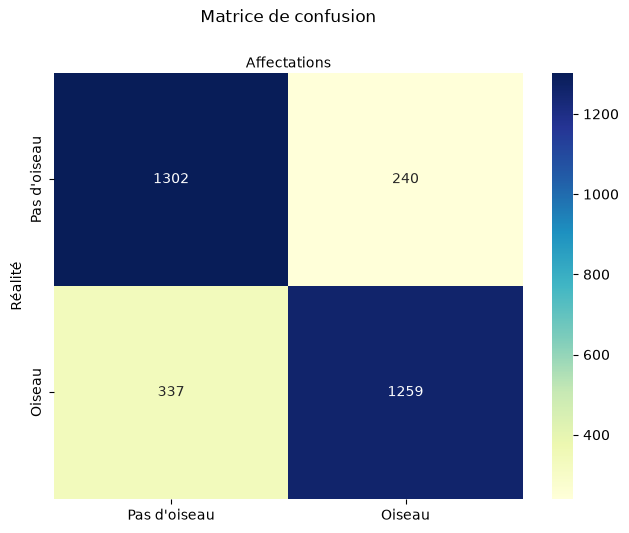

In [403]:
# Matrice de confusion
confusion_svmLin = pd.DataFrame(confusion_matrix(ytest, yPred_svmLin), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_svmLin), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [404]:
## Rapport de classification
metrics_classifReport = classification_report(ytest, yPred_svmLin, target_names=libelle)
print(metrics_classifReport)

              precision    recall  f1-score   support

Pas d'oiseau       0.79      0.84      0.82      1542
      Oiseau       0.84      0.79      0.81      1596

    accuracy                           0.82      3138
   macro avg       0.82      0.82      0.82      3138
weighted avg       0.82      0.82      0.82      3138



La SVM Linéaire présente des performances sensiblement très proches de ceux de la Régression Logistique. Cela semble donc impliquer que, malgré ce que nous pourrions penser au vu de la grande quantité de données, ces derniers sont linéairement séparables.
Par curiosité, nous regardons ce que cela donnerait si nous considérions une séparation non linéaire avec un SVM Radial Basis Function kernel.

#### SVM RBF

In [405]:
svmRBF = SVC(kernel = 'rbf', random_state=42)
cross_svmRBF = cross_validate(svmRBF, Xtrain, ytrain, cv = skf, return_train_score=True, scoring='accuracy', n_jobs=-1)

In [406]:
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {cross_svmRBF['train_score'].mean()*100:.2f}%, pour un écart-type de {cross_svmRBF['train_score'].std():.4f}")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {cross_svmRBF['test_score'].mean()*100:.2f}%, pour un écart-type de {cross_svmRBF['test_score'].std():.4f}")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 88.14%, pour un écart-type de 0.0007
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 85.29%, pour un écart-type de 0.0021


In [407]:
svmRBF_default = svmRBF.fit(Xtrain, ytrain)
yPred_svmRBF = svmRBF_default.predict(Xtest)

print(f"Sur les données de test, nous obtenons une accuracy de {svmRBF_default.score(Xtest, ytest)*100:.2f}%")

Sur les données de test, nous obtenons une accuracy de 84.51%


Avec une SVM RBF (avec les hyperparamètres par défaut), nous constatons des performances bien meilleures. En effet, nous obtenons une accuracy moyenne sur les ensembles d'apprentissage en validation croisée de 88.14% (85.29% sur les ensembles de validation) supérieure de près de 6 points de pourcentages. Nous pouvons tout de même supposer un surapprentissage.

In [408]:
grille_svmRBF = {'gamma': np.linspace(0,1,100)}
svmRBF = SVC(kernel='rbf', random_state=42)
best_svmRBF = RandomizedSearchCV(estimator = svmRBF, param_distributions = grille_svmRBF, cv = skf, scoring='accuracy', n_jobs=-1, random_state=42)
best_svmRBF.fit(Xtrain, ytrain)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=SVC(random_state=42), n_jobs=-1,
                   param_distributions={'gamma': array([0.        , 0.01010101, 0.02020202, 0.03030303, 0.04040404,
       0.05050505, 0.06060606, 0.07070707, 0.08080808, 0.09090909,
       0.1010101 , 0.11111111, 0.12121212, 0.13131313, 0.14141414,
       0.15151515, 0.16161616, 0.17171717, 0.181...
       0.70707071, 0.71717172, 0.72727273, 0.73737374, 0.74747475,
       0.75757576, 0.76767677, 0.77777778, 0.78787879, 0.7979798 ,
       0.80808081, 0.81818182, 0.82828283, 0.83838384, 0.84848485,
       0.85858586, 0.86868687, 0.87878788, 0.88888889, 0.8989899 ,
       0.90909091, 0.91919192, 0.92929293, 0.93939394, 0.94949495,
       0.95959596, 0.96969697, 0.97979798, 0.98989899, 1.        ])},
                   random_state=42, scoring='accuracy')

In [409]:
best_svmRBF_eval=best_svmRBF.best_estimator_
print("Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le SVM RBF : \n {}; \n nous obtenons une accuracy de {:.2f}% sur les données d'apprentissage et de {:.2f}% sur les données de test.".format(best_svmRBF.best_params_, best_svmRBF_eval.score(Xtrain, ytrain)*100, best_svmRBF_eval.score(Xtest, ytest)*100))
yPred_svmRBF = best_svmRBF_eval.predict(Xtest)

Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le SVM RBF : 
 {'gamma': 0.10101010101010102}; 
 nous obtenons une accuracy de 97.07% sur les données d'apprentissage et de 83.94% sur les données de test.


Text(0.5, 427.9555555555555, 'Affectations')

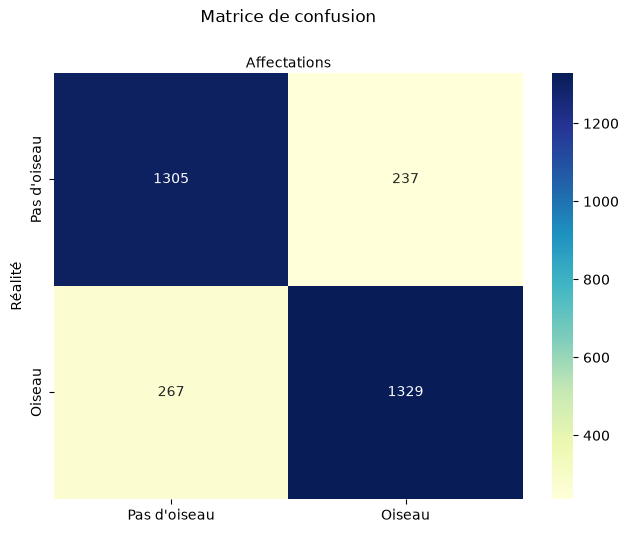

In [410]:
# Matrice de confusion
confusion_svmRBF = pd.DataFrame(confusion_matrix(ytest, yPred_svmRBF), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_svmRBF), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [411]:
## Rapport de classification
print(classification_report(ytest, yPred_svmRBF, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.83      0.85      0.84      1542
      Oiseau       0.85      0.83      0.84      1596

    accuracy                           0.84      3138
   macro avg       0.84      0.84      0.84      3138
weighted avg       0.84      0.84      0.84      3138



Avec la "meilleure" configuration d'hyperparamètres trouvée par RandomizedSearchCV, nous constatons une dégradation des performances avec un surapprentissage plus visible. Nous supposons que notre grille ne doit pas être bien réglée.

#### XGBoost

In [412]:
model_XGBoost = XGBClassifier(random_state=42)
cross_XGBoost = cross_validate(model_XGBoost, Xtrain, ytrain, cv = skf, return_train_score=True, scoring='accuracy', n_jobs=-1)

In [413]:
print(f"Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de {cross_XGBoost['train_score'].mean()*100:.2f}%, pour un écart-type de {cross_XGBoost['train_score'].std():.4f}")
print(f"Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de {cross_XGBoost['test_score'].mean()*100:.2f}%, pour un écart-type de {cross_XGBoost['test_score'].std():.4f}")

Sur les données d'apprentissage en validation croisée, nous obtenons une accuracy moyenne de 99.82%, pour un écart-type de 0.0002
Sur les données de validation en validation croisée, nous obtenons une accuracy moyenne de 84.00%, pour un écart-type de 0.0022


In [414]:
XGBoost_default = model_XGBoost.fit(Xtrain, ytrain)
yPred_XGBoost = XGBoost_default.predict(Xtest)

print(f"Sur les données de test, nous obtenons une accuracy de {XGBoost_default.score(Xtest, ytest)*100:.2f}%")

Sur les données de test, nous obtenons une accuracy de 83.81%


##### Recherche des meilleurs hyperparamètres

In [415]:
grille_XGBoost = {
    'subsample': [0.4, 0.5, 0.6, 0.7],
    'scale_pos_weight': [50, 75, 100, 125],
    'reg_lambda': [1.5, 2.0, 2.5, 3.0],
    'reg_alpha': [1.0, 1.5, 2.0],
    'n_estimators': [300, 500, 1000],
    'min_child_weight': [1, 3, 5],
    'max_depth': [3, 4, 5],
    'max_delta_step': [5, 10, 15],
    'learning_rate': [0.01, 0.05, 0.1],
    'gamma': [0.05, 0.1, 0.2],
    'colsample_bytree': [0.6, 0.7, 0.8]
}
# Initialiser la recherche par échantillonnage aléatoire
best_XGBoost = RandomizedSearchCV(estimator=XGBClassifier(), param_distributions=grille_XGBoost, cv=skf, random_state=42, n_jobs=-1, scoring='accuracy', n_iter=50, return_train_score=True)

# Lancer la recherche des meilleurs hyperparamètres
best_XGBoost.fit(Xtrain, ytrain)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_...
                   param_distributions={'colsample_bytree': [0.6, 0.7, 0.8],
                                        'gamma': [0.05, 0.1, 0.2],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_delta_step': [5, 10, 15],
                                        'max_depth': [3, 4, 5],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [300, 500, 1000],
                                        'reg_alpha': [1.0, 1.5, 2.0],
                                        'reg_lambda': [1.5, 2.0, 2.5, 3.0],
                                        'scale_pos_weight': [50, 75, 100, 125],
                                        'subsample': [0.4, 0.5, 0.6, 0.7]},
                   random_state=42, return_train_score=True,
                   scoring='accuracy')

In [416]:
best_XGBoost_eval=best_XGBoost.best_estimator_
print("Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le XGBoost : \n {}; \n nous obtenons une accuracy de {:.2f}% sur les données d'apprentissage et de {:.2f}% sur les données de test.".format(best_XGBoost.best_params_, best_XGBoost_eval.score(Xtrain, ytrain)*100, best_XGBoost_eval.score(Xtest, ytest)*100))
yPred_XGBoost = best_XGBoost_eval.predict(Xtest)

Avec la meilleure configuration de paramètres trouvée par RandomizedSearchCV pour le XGBoost : 
 {'subsample': 0.6, 'scale_pos_weight': 50, 'reg_lambda': 1.5, 'reg_alpha': 2.0, 'n_estimators': 1000, 'min_child_weight': 1, 'max_depth': 5, 'max_delta_step': 10, 'learning_rate': 0.1, 'gamma': 0.2, 'colsample_bytree': 0.7}; 
 nous obtenons une accuracy de 99.43% sur les données d'apprentissage et de 82.06% sur les données de test.


Text(0.5, 427.9555555555555, 'Affectations')

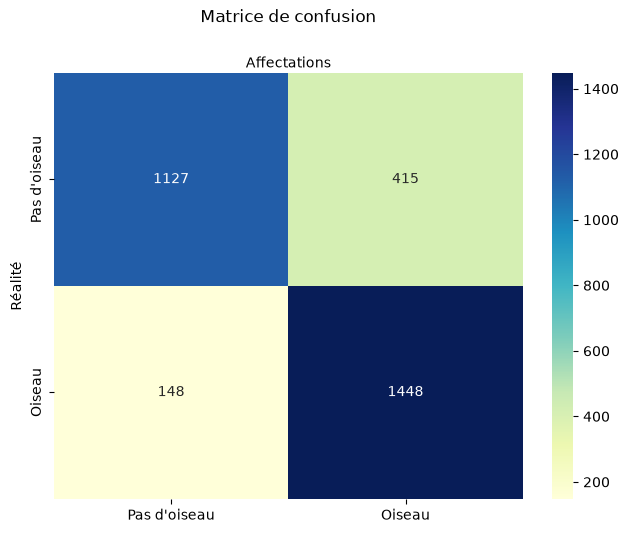

In [417]:
# Matrice de confusion
confusion_XGBoost = pd.DataFrame(confusion_matrix(ytest, yPred_XGBoost), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_XGBoost), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [418]:
## Rapport de classification
print(classification_report(ytest, yPred_XGBoost, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.88      0.73      0.80      1542
      Oiseau       0.78      0.91      0.84      1596

    accuracy                           0.82      3138
   macro avg       0.83      0.82      0.82      3138
weighted avg       0.83      0.82      0.82      3138



Avec le XGBoost, nous constatons des performances sur l'accuracy similaires au Random Forest et à la SVM RBF optimisée. EN regardant la matrice de confusion, nous constatons qu'avec le XGBoost avec la meilleure configuration d'hyperparamètres, nous avons un modèle qui est largement meilleure à prédire les audios contenant des chants d'oiseaux plutôt que sans. Pour être plus précis, ce modèle à tendance à affecter énormément d'audios à la valeur 'Oiseau'.

### Réseau de neurones

Pour finir, nous construisons un MLP. Celui-ci comporte deux couches cachés avec peu de neurones (accroître la complexité dégrade la qualité des performances ici)

In [419]:
model = Sequential()

# Définition du modèle fully-connected
model = Sequential([
    Dense(16, activation='relu', input_shape = (Xtrain.shape[1],)), # couche fully-connected
    Dense(8, activation='relu'), # couche fully-connected
    Dense(2, activation='softmax') # couche de sortie
    ])

# Compilation du modèle
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy', keras.metrics.AUC(name='auc')])

# Entraînement du modèle
history = model.fit(Xtrain, to_categorical(ytrain), epochs=20, batch_size=32, validation_split=0.2, verbose=1)

# Évaluation du modèle en l'appliquant sur l'ensemble de test
score_MLP = model.evaluate(Xtest, to_categorical(ytest), verbose=1)
print("score de l'ensemble de test : ", score_MLP)

Epoch 1/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7706 - auc: 0.8482 - loss: 0.4860 - val_accuracy: 0.7989 - val_auc: 0.8782 - val_loss: 0.4399
Epoch 2/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8121 - auc: 0.8887 - loss: 0.4219 - val_accuracy: 0.8164 - val_auc: 0.8936 - val_loss: 0.4139
Epoch 3/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8214 - auc: 0.8991 - loss: 0.4021 - val_accuracy: 0.8228 - val_auc: 0.8985 - val_loss: 0.4051
Epoch 4/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8288 - auc: 0.9063 - loss: 0.3884 - val_accuracy: 0.8244 - val_auc: 0.9011 - val_loss: 0.3993
Epoch 5/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8332 - auc: 0.9105 - loss: 0.3797 - val_accuracy: 0.8260 - val_auc: 0.9059 - val_loss: 0.3888
Epoch 6/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8378 - auc: 0.9134 - loss: 0.3736 - val_accuracy: 0.8292 - val_auc: 0.9080 - val_loss: 0.3846
Epoch 7/20
314/314 ━━━━━━━━━━━━━━━━━━━━ 

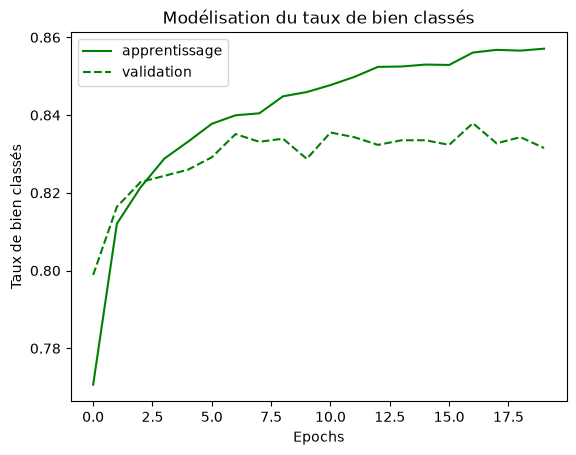

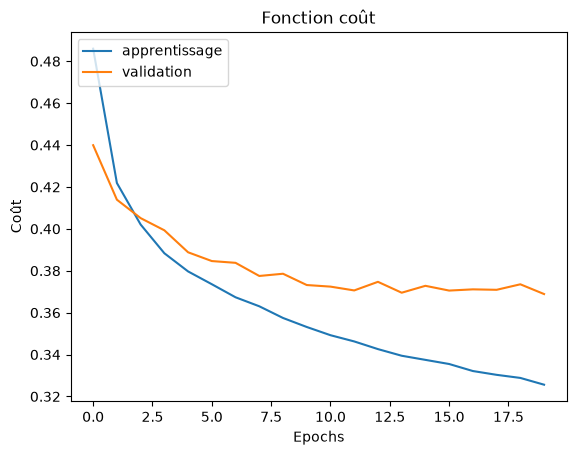

In [420]:
# Graphique en courbe représentant l'évolution de l'accuracy selon le nombre d'epochs
plt.figure()
plt.plot(history.history['accuracy'], "g", label="Taux de bien classés de l'ensemble d'apprentissage")
plt.plot(history.history['val_accuracy'], "g--", label="Taux de bien classés de l'ensemble de validation")
plt.title('Modélisation du taux de bien classés')
plt.ylabel('Taux de bien classés')
plt.xlabel('Epochs')
plt.legend(['apprentissage', 'validation'], loc='upper left')

# Graphique en courbe représentant l'évolution de la fonction coût selon le nombre d'epochs
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Fonction coût')
plt.ylabel('Coût')
plt.xlabel('Epochs')
plt.legend(['apprentissage', 'validation'], loc='upper left')
plt.show()

99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


Text(0.5, 427.9555555555555, 'Affectations')

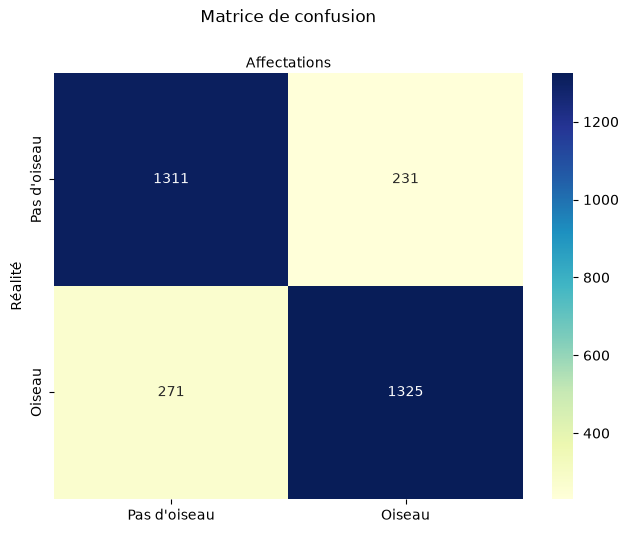

In [421]:
# 1. Obtenir les prédictions (probabilités)
yPred_probs_MLP = model.predict(Xtest)

# 2. Convertir les probabilités en indices de classes
yPred_MLP = np.argmax(yPred_probs_MLP, axis=1)

# Note : si y_test est encodé en one-hot, convertissez-le aussi :
# y_true = np.argmax(y_test, axis=1)
y_true = ytest 

# 3. Calculer et afficher la matrice
confusion_MLP = pd.DataFrame(confusion_matrix(ytest, yPred_MLP), index=libelle, columns=libelle)
fig, ax = plt.subplots()
tick_marks = np.arange(len(libelle))
plt.xticks(tick_marks, libelle)
plt.yticks(tick_marks, libelle)
# create heatmap
sns.heatmap(pd.DataFrame(confusion_MLP), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matrice de confusion', y=1.1)
plt.ylabel('Réalité')
plt.xlabel('Affectations')

In [422]:
## Rapport de classification
print(classification_report(ytest, yPred_MLP, target_names=libelle))

              precision    recall  f1-score   support

Pas d'oiseau       0.83      0.85      0.84      1542
      Oiseau       0.85      0.83      0.84      1596

    accuracy                           0.84      3138
   macro avg       0.84      0.84      0.84      3138
weighted avg       0.84      0.84      0.84      3138



Nous constatons que les performances issues du MLP à 2 couches cachés sont meilleures qu'avec les algorithmes de Machine Learning. En effet, nous obtenons un taux de bien classés sur l'ensemble de test de 84.03% (bien mieux qu'avec les modèles prédictifs précédents sauf le SVM RBF avec les hyperparamètres par défaut), ce sans avoir de surapprentissage (taux de bien classés sur l'ensemble d'apprentissage autour de 86% dans les dernières epochs).

### Tableau récapitulatif

In [ ]:
df_récap = pd.DataFrame({
    "Modèle": ["Régression logistique", "Arbre de décision", "Forêt aléatoire", "SVC linéaire", "SVM RBF", "XGBoost", "MLP 2 couches"],
    "Accuracy train default params": [regLog_default.score(Xtrain, ytrain), decTree_default.score(Xtrain, ytrain), rf_default.score(Xtrain, ytrain), svmLin_default.score(Xtrain, ytrain), svmRBF_default.score(Xtrain, ytrain), XGBoost_default.score(Xtrain, ytrain), history.history['accuracy'][-1]],
    "Accuracy test default params": [regLog_default.score(Xtest, ytest), decTree_default.score(Xtest, ytest), rf_default.score(Xtest, ytest), svmLin_default.score(Xtest, ytest), svmRBF_default.score(Xtest, ytest), XGBoost_default.score(Xtest, ytest), score_MLP[1]],
    "Accuracy train best params": [np.nan, best_decTree_eval.score(Xtrain, ytrain), best_rf_eval.score(Xtrain, ytrain), best_svmLin_eval.score(Xtrain, ytrain), best_svmRBF_eval.score(Xtrain, ytrain), best_XGBoost_eval.score(Xtrain, ytrain), np.nan],
    "Accuracy test best params": [np.nan, best_decTree_eval.score(Xtest, ytest), best_rf_eval.score(Xtest, ytest), best_svmLin_eval.score(Xtest, ytest), best_svmRBF_eval.score(Xtest, ytest), best_XGBoost_eval.score(Xtest, ytest), np.nan]
    })

print(df_récap)

                  Modèle  Accuracy train default params  \
0  Régression logistique                       0.825366   
1      Arbre de décision                       1.000000   
2        Forêt aléatoire                       1.000000   
3           SVC linéaire                       0.824490   
4                SVM RBF                       0.881533   
5                XGBoost                       0.995618   
6          MLP 2 couches                       0.858679   

   Accuracy train best params  Accuracy test default params  \
0                         NaN                      0.816444   
1                    0.794535                      0.743467   
2                    1.000000                      0.835564   
3                    0.824251                      0.816444   
4                    0.970682                      0.845124   
5                    0.994344                      0.838113   
6                         NaN                      0.840344   

   Accuracy test best 

### Conclusion

Globalement, nous retenons que les descripteurs audios sont de très bonnes features pour prédire la présence/absence de chants d'oiseaux dans les audios. En effet, nous obtenons généralement un taux de bien classés sur l'échantillon de test autour de 82%-83%, avec plus ou moins de surapprentissage. Nous retenons notamment la SVM RBF et le MLP à deux couches cachés qui présentent une accuracy sur l'échantillon de test de plus de 84% avec un faible surapprentissage. La plupart des modèles sont autant efficaces dans la prédiction de la présence de chants d'oiseaux et l'absence de chants d'oiseaux. A la nuance que le modèle XGBoost est bien plus efficace pour détecter la présence de chants d'oiseaux (mais cela est causé par une tendance à affecter facilement cette catégorie).